In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

from lightgbm import LGBMClassifier
from lightgbm import early_stopping, log_evaluation
import lightgbm as lgb


In [2]:
df = pd.read_csv("../data/dataset/data_v5.csv")
df['location'] = df['location'].notna().astype(int)
df.head()

,stt,content,reactions,replies,posted_time,location,contact,disaster_type,affected_people,infrastructure_damage,...,phuong_xa,nha,chỗ ở & nơi trú ẩn,liên lạc & thông tin,lương thực & nước uống,phương tiện & cứu hộ,thuốc men & hỗ trợ y tế,"vật dụng sinh hoạt (áo phao, đèn pin, quần áo, mền chăn)",affected_people_log,affected_people_minmax
0,1,"CẦN HỖ TRỢ LƯƠNG THỰC THỰC PHẨM, SẠC, ĐÈN PIN ...",82,29,1w,1,1,2,4.0,0,...,Kim Long,nhà số 9 kiệt 34 An Ninh,0,1,1,0,0,1,1.609438,0.026667
1,2,"CẦN CỨU KhẨN CẤP Khu vực dân Vĩnh Điện, Điện B...",0,0,1w,1,0,2,0.0,1,...,Vĩnh Điện,NaN,0,1,1,0,1,0,0.000000,0.000000
2,4,"-Người thân em đang ở địa chỉ định vị này,sáng...",0,0,1w,1,1,2,0.0,1,...,Gò Nổi,thôn Tây An,1,1,1,1,1,0,0.000000,0.000000
3,5,"Anh chồng mình là Nguyễn Xuân Năm, bị ngộ độc ...",0,0,1w,1,0,2,1.0,0,...,Không rõ,quán dê,0,0,0,1,0,0,0.693147,0.006667
4,6,"Đào Thị Quy. Nhà có 1 bé 4 tuổi, 1 bé 6 tuổi, ...",1,0,17h,1,1,2,6.0,1,...,Mỹ Hiệp,"đội 9, thôn Hòa Nghĩa",1,1,1,1,1,1,1.945910,0.040000


In [3]:
print(df.columns.tolist())

['stt', 'content', 'reactions', 'replies', 'posted_time', 'location', 'contact', 'disaster_type', 'affected_people', 'infrastructure_damage', 'needs', 'is_isolated', 'deathly', 'has_emergency_terms', 'has_emotional_terms', 'has_emphasis', 'label', 'confident', 'tinh_tp', 'quan_huyen', 'phuong_xa', 'nha', 'chỗ ở & nơi trú ẩn', 'liên lạc & thông tin', 'lương thực & nước uống', 'phương tiện & cứu hộ', 'thuốc men & hỗ trợ y tế', 'vật dụng sinh hoạt (áo phao, đèn pin, quần áo, mền chăn)', 'affected_people_log', 'affected_people_minmax']


In [4]:
df['label'].unique()

array(['CAO', 'TRUNG BÌNH', 'THẤP', 'Cao', 'Trung Bình'], dtype=object)

In [5]:
df['confident'].unique()

array(['CAO', 'THẤP', 'Cao', 'CAO '], dtype=object)

In [6]:
# ==================== 2. CHUẨN HÓA NHÃN ====================
# ---- 2.1 MỨC ĐỘ KHẨN CẤP (label) ----
df['urgency'] = (
    df['label']
    .astype(str)
    .str.strip()      # bỏ khoảng trắng
    .str.upper()      # thống nhất chữ hoa
)

df['urgency'] = df['urgency'].replace({
    'CAO': 'CAO',
    'TRUNG BÌNH': 'TRUNG BÌNH',
    'THẤP': 'THẤP'
})

# ---- 2.2 ĐỘ TIN CẬY (confident) ----
df['confidence'] = (
    df['confident']
    .astype(str)
    .str.strip()      # xử lý 'CAO '
    .str.upper()      # xử lý 'Cao'
)

df['confidence'] = df['confidence'].replace({
    'CAO': 'CAO',
    'THẤP': 'THẤP'
})

# ---- Giữ lại đúng nhãn hợp lệ ----
df = df[df['urgency'].isin(['THẤP', 'TRUNG BÌNH', 'CAO'])]
df = df[df['confidence'].isin(['THẤP', 'CAO'])]

In [7]:
# ==================== 3. FEATURE ====================
df = df.rename(columns={
    'lương thực & nước uống': 'food_water',
    'thuốc men & hỗ trợ y tế': 'medical_support',
    'phương tiện & cứu hộ': 'rescue_transport',
    'chỗ ở & nơi trú ẩn': 'shelter',
    'vật dụng sinh hoạt (áo phao, đèn pin, quần áo, mền chăn)': 'daily_supplies'
})

urgency_features = [
    'affected_people',
    'deathly',
    'is_isolated',
    'infrastructure_damage',
    'food_water',
    'medical_support',
    'rescue_transport',
    'shelter',
    'daily_supplies'
]

confidence_features = [
    'has_emotional_terms',
    'has_emphasis',
    'contact',
    'location'
]
X_u = df[urgency_features]
X_c = df[confidence_features]


In [8]:
# ==================== 4. ENCODE NHÃN ====================
le_u = LabelEncoder()
le_c = LabelEncoder()

y_u = le_u.fit_transform(df['urgency'])
y_c = le_c.fit_transform(df['confidence'])

In [9]:
# ==================== 5. SPLIT 7–2–1 ====================
def split_721(X, y):
    X_tmp, X_test, y_tmp, y_test = train_test_split(
        X, y, test_size=0.1, stratify=y, random_state=42
    )
    X_train, X_val, y_train, y_val = train_test_split(
        X_tmp, y_tmp, test_size=2/9, stratify=y_tmp, random_state=42
    )
    return X_train, X_val, X_test, y_train, y_val, y_test

Xu_tr, Xu_val, Xu_te, yu_tr, yu_val, yu_te = split_721(X_u, y_u)

# CONFIDENCE: chỉ train nếu có đủ 2 lớp
unique_conf = np.unique(y_c)

Xc_tr, Xc_val, Xc_te, yc_tr, yc_val, yc_te = split_721(X_c, y_c)

In [10]:
urgency_model = LGBMClassifier(
    objective='multiclass',
    num_class=3,
    n_estimators=300,
    learning_rate=0.05,
    class_weight='balanced',
    random_state=42
)

confidence_model = LGBMClassifier(
    objective='binary',
    n_estimators=200,
    learning_rate=0.05,
    class_weight='balanced',
    random_state=42
)

urgency_model.fit(
    Xu_tr, yu_tr,
    eval_set=[(Xu_val, yu_val)],
    eval_metric='multi_logloss'
)

confidence_model.fit(
    Xc_tr, yc_tr,
    eval_set=[(Xc_val, yc_val)],
    eval_metric='binary_logloss'
)

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000385 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 31
[LightGBM] [Info] Number of data points in the train set: 337, number of used features: 9
[LightGBM] [Info] Start training from score -1.098612
[LightGBM] [Info] Start training from score -1.098612
[LightGBM] [Info] Start training from score -1.098612
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits w

,boosting_type,'gbdt'
,num_leaves,31
,max_depth,-1
,learning_rate,0.05
,n_estimators,200
,subsample_for_bin,200000
,objective,'binary'
,class_weight,'balanced'
,min_split_gain,0.0
,min_child_weight,0.001
,min_child_samples,20


In [11]:
# ==================== 7. ĐÁNH GIÁ & CONFUSION MATRIX ====================
def evaluate(model, X_tr, y_tr, X_val, y_val, X_te, y_te, labels, title):
    print("\n" + "="*75)
    print(title.center(75))
    print("="*75)

    for name, X, y in [
        ("Train", X_tr, y_tr),
        ("Validation", X_val, y_val),
        ("Test", X_te, y_te)
    ]:
        pred = model.predict(X)
        print(f"Accuracy ({name:<10}): {accuracy_score(y, pred):.2%}")

    pred_test = model.predict(X_te)
    print("\nClassification report (TEST SET):")
    print(classification_report(y_te, pred_test, target_names=labels))

    # ===== CONFUSION MATRIX =====
    cm = confusion_matrix(y_te, pred_test)

    plt.figure(figsize=(6,5))
    plt.imshow(cm, cmap="Blues")
    plt.colorbar(fraction=0.046)

    plt.title(title)
    plt.xlabel("Predicted label")
    plt.ylabel("True label")

    plt.xticks(range(len(labels)), labels, rotation=20)
    plt.yticks(range(len(labels)), labels)

    for i in range(len(labels)):
        for j in range(len(labels)):
            plt.text(
                j, i, cm[i, j],
                ha='center', va='center',
                color='white' if cm[i, j] > cm.max()/2 else 'black'
            )

    plt.tight_layout()
    plt.show()


                     Confusion Matrix - MỨC ĐỘ KHẨN CẤP                    
Accuracy (Train     ): 75.67%
Accuracy (Validation): 56.70%
Accuracy (Test      ): 48.98%

Classification report (TEST SET):
              precision    recall  f1-score   support

         CAO       0.70      0.54      0.61        26
        THẤP       0.30      0.43      0.35         7
  TRUNG BÌNH       0.37      0.44      0.40        16

    accuracy                           0.49        49
   macro avg       0.46      0.47      0.45        49
weighted avg       0.53      0.49      0.50        49



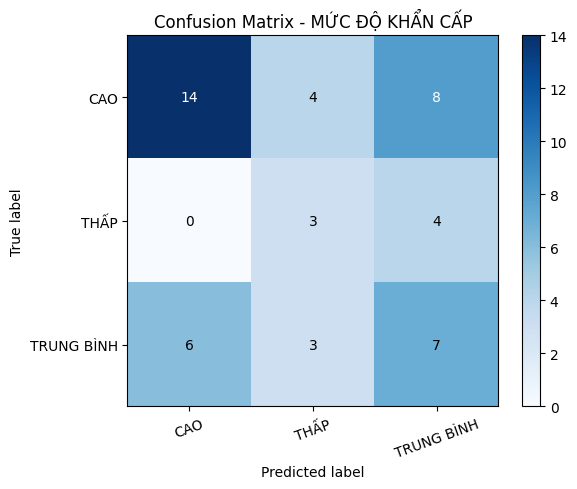

In [12]:
evaluate(
    urgency_model,
    Xu_tr, yu_tr,
    Xu_val, yu_val,
    Xu_te, yu_te,
    le_u.classes_,
    "Confusion Matrix - MỨC ĐỘ KHẨN CẤP"
)


                  Confusion Matrix - ĐỘ TIN CẬY THÔNG TIN                  
Accuracy (Train     ): 93.77%
Accuracy (Validation): 96.91%
Accuracy (Test      ): 91.84%

Classification report (TEST SET):
              precision    recall  f1-score   support

         CAO       0.93      0.98      0.95        43
        THẤP       0.75      0.50      0.60         6

    accuracy                           0.92        49
   macro avg       0.84      0.74      0.78        49
weighted avg       0.91      0.92      0.91        49



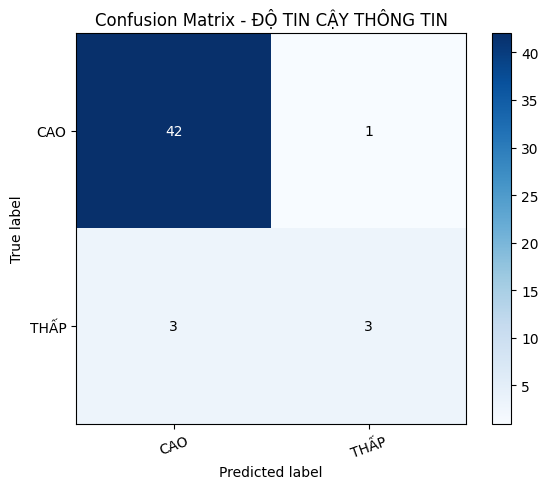

In [13]:

evaluate(
    confidence_model,
    Xc_tr, yc_tr,
    Xc_val, yc_val,
    Xc_te, yc_te,
    le_c.classes_,
    "Confusion Matrix - ĐỘ TIN CẬY THÔNG TIN"
)
